In [1]:
import os, time, requests, pandas as pd
import matplotlib.pyplot as plt
from dateutil import tz
from tabulate import tabulate
from getpass import getpass

API_BASE = "https://api.electricitymaps.com/v3"

# --- Choose how to query ---
ZONE = "NL"     # Netherlands zone code
LAT, LON = None, None  # or set to coordinates; if both set, geolocation is used

# Optional: try the newer electricity-mix endpoints (usually paid)
USE_ELECTRICITY_MIX = False  # set True if your plan supports them  :contentReference[oaicite:1]{index=1}

# --- Auth token ---
TOKEN = os.getenv("ELECTRICITYMAPS_API_TOKEN")
if not TOKEN:
    TOKEN = getpass("Enter your Electricity Maps API key (will not echo): ")

HEADERS = {"auth-token": TOKEN}  # API expects this header  :contentReference[oaicite:2]{index=2}


In [2]:
def build_params(zone=None, lat=None, lon=None):
    if zone:
        return {"zone": zone}
    if lat is not None and lon is not None:
        return {"lat": lat, "lon": lon}
    return {"zone": "NL"}  # safe default

PARAMS = build_params(ZONE, LAT, LON)
PARAMS


{'zone': 'NL'}

In [3]:
def fetch_json(url, headers, params, attempts=3, timeout=20):
    last_err = None
    for k in range(attempts):
        try:
            r = requests.get(url, headers=headers, params=params, timeout=timeout)
            if r.status_code == 200:
                return r.json()
            # Helpful message if plan/endpoint mismatch
            if r.status_code in (401, 402, 403, 404):
                raise RuntimeError(f"{r.status_code} {url} :: {r.text[:200]}")
            r.raise_for_status()
        except Exception as e:
            last_err = e
            time.sleep(1.2 * (k + 1))
    raise last_err


In [4]:
def get_power_breakdown_latest(params):
    return fetch_json(f"{API_BASE}/power-breakdown/latest", HEADERS, params)

def get_power_breakdown_history(params):
    # Free plan provides ~last 24h at hourly resolution  :contentReference[oaicite:3]{index=3}
    return fetch_json(f"{API_BASE}/power-breakdown/history", HEADERS, params)

def try_electricity_mix_latest(params):
    return fetch_json(f"{API_BASE}/electricity-mix/latest", HEADERS, params)

def try_electricity_mix_history(params):
    return fetch_json(f"{API_BASE}/electricity-mix/history", HEADERS, params)


In [5]:
def to_df_from_history(payload):
    # History returns {"zone": "...", "data": [ {datetime, powerConsumptionBreakdown{...}, ...}, ... ]}
    rows = payload.get("data") or payload.get("history") or []
    if not rows:
        return pd.DataFrame()

    df = pd.json_normalize(rows, sep=".")
    # Bring breakdown keys up (e.g., 'powerConsumptionBreakdown.wind' -> 'wind')
    bcols = [c for c in df.columns if c.startswith("powerConsumptionBreakdown.")]
    rename = {c: c.split(".", 1)[1].replace(" ", "_") for c in bcols}
    df = df.rename(columns=rename)

    # Timestamps
    if "datetime" in df:
        df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
        df["datetime_local"] = df["datetime"].dt.tz_convert("Europe/Amsterdam")
        df = df.sort_values("datetime").set_index("datetime_local")

    # Fallback total if missing
    if "powerConsumptionTotal" not in df:
        if rename:
            df["powerConsumptionTotal"] = df[list(rename.values())].sum(axis=1)

    return df

def to_series_from_latest(payload):
    # Latest returns a single point; normalize and convert to a Series indexed by local time
    flat = pd.json_normalize(payload, sep=".")
    bcols = [c for c in flat.columns if c.startswith("powerConsumptionBreakdown.")]
    rename = {c: c.split(".", 1)[1].replace(" ", "_") for c in bcols}
    flat = flat.rename(columns=rename)
    if "datetime" in flat:
        ts_utc = pd.to_datetime(flat.loc[0, "datetime"], utc=True)
        ts_local = ts_utc.tz_convert("Europe/Amsterdam")
    else:
        ts_local = pd.Timestamp.utcnow().tz_localize("UTC").tz_convert("Europe/Amsterdam")
    s = flat.squeeze()
    s.name = ts_local
    return s


In [6]:
if USE_ELECTRICITY_MIX:
    try:
        hist_raw = try_electricity_mix_history(PARAMS)
        latest_raw = try_electricity_mix_latest(PARAMS)
    except Exception as e:
        print("[info] electricity-mix not available on your plan; falling back to power-breakdown.", e)
        hist_raw = get_power_breakdown_history(PARAMS)
        latest_raw = get_power_breakdown_latest(PARAMS)
else:
    hist_raw = get_power_breakdown_history(PARAMS)
    latest_raw = get_power_breakdown_latest(PARAMS)

df = to_df_from_history(hist_raw)
latest = to_series_from_latest(latest_raw)

print(f"Window points: {len(df)} (should be ~24 on free tier)")
df.head(3)


Window points: 24 (should be ~24 on free tier)


,zone,datetime,updatedAt,createdAt,fossilFreePercentage,renewablePercentage,powerConsumptionTotal,powerProductionTotal,powerImportTotal,powerExportTotal,...,powerImportBreakdown.BE,powerImportBreakdown.DE,powerImportBreakdown.GB,powerImportBreakdown.DK-DK1,powerImportBreakdown.NO-NO2,powerExportBreakdown.BE,powerExportBreakdown.DE,powerExportBreakdown.GB,powerExportBreakdown.DK-DK1,powerExportBreakdown.NO-NO2
datetime_local,,,,,,,,,,,,,,,,,,,,,
2025-09-05 22:00:00+02:00,NL,2025-09-05 20:00:00+00:00,2025-09-06T18:25:28.812Z,2025-09-02T23:30:40.524Z,18,14,11127,11439,803,1115,...,0,63,119,0,621,640,0,0,475,0
2025-09-05 23:00:00+02:00,NL,2025-09-05 21:00:00+00:00,2025-09-06T08:40:31.538Z,2025-09-02T23:30:40.524Z,18,14,10648,11118,975,1445,...,0,0,354,0,621,819,101,0,525,0
2025-09-06 00:00:00+02:00,NL,2025-09-05 22:00:00+00:00,2025-09-06T18:25:28.797Z,2025-09-02T23:31:00.369Z,21,16,10086,10271,1480,1665,...,0,860,0,0,620,924,0,101,640,0


In [7]:
def pick_sources(df, top_n=6):
    # candidate source columns = breakdown keys (exclude meta + totals)
    exclude = {"zone","datetime","updatedAt","createdAt","powerConsumptionTotal",
               "powerProductionTotal","powerImportTotal","powerExportTotal",
               "renewablePercentage","fossilFreePercentage","isEstimated","estimationMethod"}
    candidates = [c for c in df.columns if c not in exclude and not c.startswith("power")]
    totals = df[candidates].sum().sort_values(ascending=False)
    top = list(totals.head(top_n).index)
    other = [c for c in candidates if c not in top]
    return top, other, totals

top_sources, other_sources, totals_mwh = pick_sources(df, top_n=6)

# Percent shares
for c in top_sources + (["other"] if other_sources else []):
    base = df["powerConsumptionTotal"].replace(0, pd.NA)
    if c == "other":
        df["other"] = df[other_sources].sum(axis=1) if other_sources else 0.0
        df["other_pct"] = 100 * df["other"] / base
    else:
        df[f"{c}_pct"] = 100 * df[c] / base

avg_pct = df[[f"{c}_pct" for c in top_sources]].mean().sort_values(ascending=False)
print("Top by energy over window (MWh ~ MW*1h):")
print(tabulate(totals_mwh.loc[top_sources].reset_index().values,
               headers=["Source","Total (MWh)"], floatfmt=".1f"))
print("\nAverage share over window (%):")
print(tabulate(avg_pct.reset_index().values, headers=["Source","Avg %"], floatfmt=".1f"))


Top by energy over window (MWh ~ MW*1h):
Source      Total (MWh)
--------  -------------
solar            118638
gas               89133
wind              21772
coal              20269
biomass           14567
nuclear           13915

Average share over window (%):
Source         Avg %
-----------  -------
gas_pct         35.1
solar_pct       32.4
coal_pct         8.5
wind_pct         7.6
biomass_pct      5.7
nuclear_pct      5.0


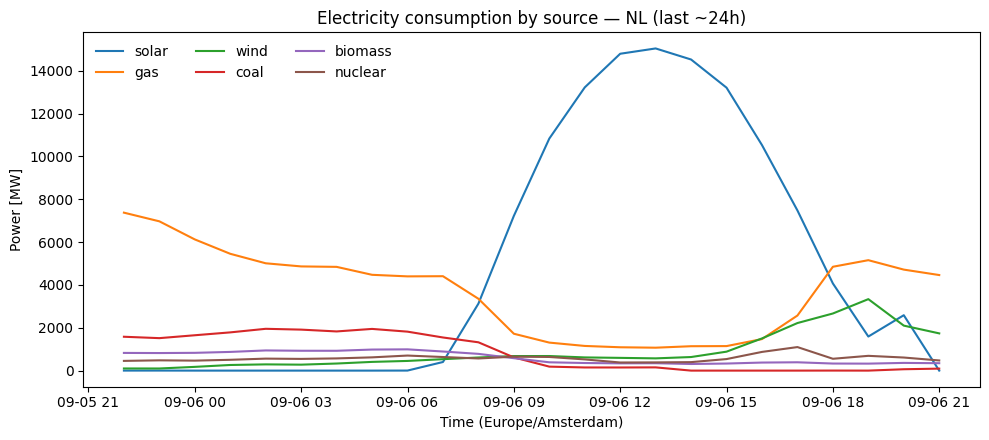

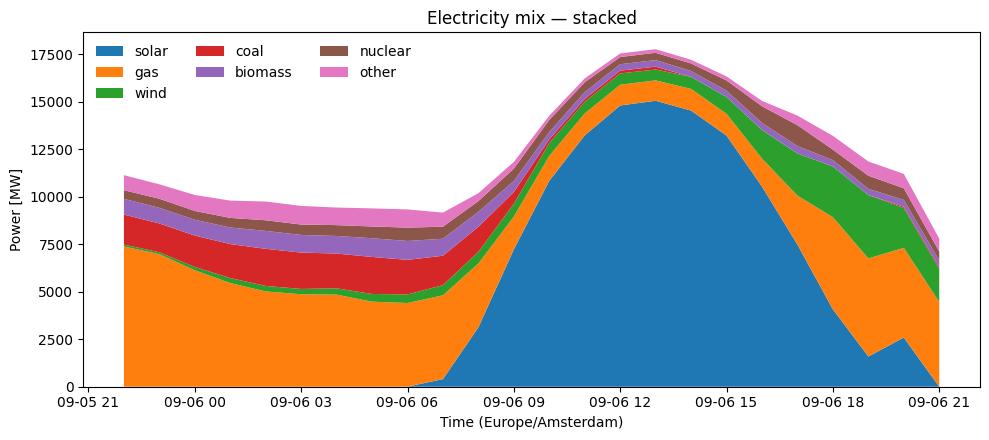

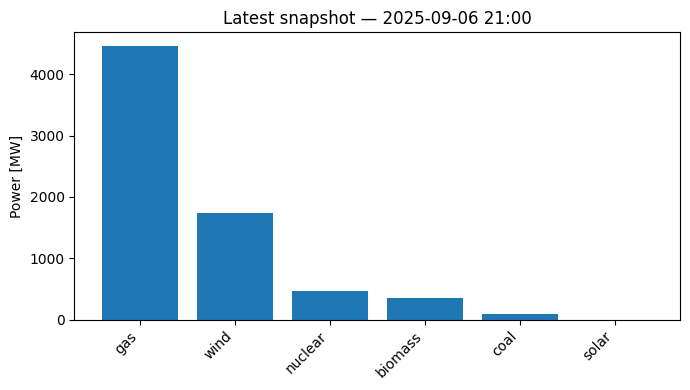

In [8]:
plt.figure(figsize=(10,4.5))
for c in top_sources:
    plt.plot(df.index, df[c], label=c)
plt.xlabel("Time (Europe/Amsterdam)")
plt.ylabel("Power [MW]")
plt.title("Electricity consumption by source — NL (last ~24h)")
plt.legend(ncol=3, frameon=False)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,4.5))
stack_cols = top_sources + (["other"] if other_sources else [])
plt.stackplot(df.index, *(df[stack_cols].T.values), labels=stack_cols)
plt.xlabel("Time (Europe/Amsterdam)")
plt.ylabel("Power [MW]")
plt.title("Electricity mix — stacked")
plt.legend(ncol=3, frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

if len(top_sources):
    order = latest[top_sources].sort_values(ascending=False).index
    plt.figure(figsize=(7,4))
    plt.bar(order, latest[order])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Power [MW]")
    plt.title(f"Latest snapshot — {latest.name.strftime('%Y-%m-%d %H:%M')}")
    plt.tight_layout()
    plt.show()


In [9]:
outdir = "output"
os.makedirs(outdir, exist_ok=True)
df_out = df.copy()
df_out.index.name = "datetime_local"
csv_path = os.path.join(outdir, "nl_electricity_mix_24h.csv")
df_out.to_csv(csv_path)
csv_path


'output\\nl_electricity_mix_24h.csv'

==================================================


In [10]:
def get_carbon_intensity_latest(params, emission_factor_type="lifecycle", disable_estimations=False):
    """
    Call /v3/carbon-intensity/latest.
    - emission_factor_type: "lifecycle" (default) or "direct"
    - disable_estimations: True/False
    Docs: returns { zone, carbonIntensity, datetime, updatedAt, emissionFactorType, isEstimated, estimationMethod }
    """
    q = dict(params)  # copy
    if emission_factor_type:
        q["emissionFactorType"] = emission_factor_type
    if disable_estimations:
        q["disableEstimations"] = "true"
    url = f"{API_BASE}/carbon-intensity/latest"
    return fetch_json(url, HEADERS, q)


In [11]:
def get_carbon_intensity_latest(params, emission_factor_type="lifecycle", disable_estimations=False):
    """
    Call /v3/carbon-intensity/latest.
    - emission_factor_type: "lifecycle" (default) or "direct"
    - disable_estimations: True/False
    Docs: returns { zone, carbonIntensity, datetime, updatedAt, emissionFactorType, isEstimated, estimationMethod }
    """
    q = dict(params)  # copy
    if emission_factor_type:
        q["emissionFactorType"] = emission_factor_type
    if disable_estimations:
        q["disableEstimations"] = "true"
    url = f"{API_BASE}/carbon-intensity/latest"
    return fetch_json(url, HEADERS, q)


In [13]:
# Patch: (re)define ci_latest_to_series
import pandas as pd

def ci_latest_to_series(payload):
    """
    Convert /v3/carbon-intensity/latest payload to a Pandas Series.
    Series.name = local timestamp (Europe/Amsterdam).
    Adds convenience fields:
      - carbonIntensity_g_per_kWh
      - carbonIntensity_kg_per_MWh  (numerically the same value)
    """
    if not payload:
        raise ValueError("Empty payload from /carbon-intensity/latest")

    s = pd.json_normalize(payload, sep=".").squeeze()

    # Timestamp -> Europe/Amsterdam
    dt = s.get("datetime")
    if pd.isna(dt) if "datetime" in s else True:
        ts_local = pd.Timestamp.utcnow().tz_localize("UTC").tz_convert("Europe/Amsterdam")
    else:
        ts_local = pd.to_datetime(dt, utc=True).tz_convert("Europe/Amsterdam")
    s.name = ts_local

    # Convenience aliases
    if "carbonIntensity" in s:
        val = float(s["carbonIntensity"])
        s["carbonIntensity_g_per_kWh"] = val
        s["carbonIntensity_kg_per_MWh"] = val

    return s


In [14]:
ci_raw = get_carbon_intensity_latest(PARAMS, emission_factor_type="lifecycle", disable_estimations=False)
ci_series = ci_latest_to_series(ci_raw)

print("Latest Carbon Intensity (NL):",
      f"{ci_series['carbonIntensity_g_per_kWh']:.0f} gCO₂e/kWh",
      f"@ {ci_series.name.strftime('%Y-%m-%d %H:%M %Z')}")
print("Estimated?" , bool(ci_series.get("isEstimated", False)),
      "| Method:", ci_series.get("estimationMethod", None))
ci_series


Latest Carbon Intensity (NL): 297 gCO₂e/kWh @ 2025-09-06 21:00 CEST
Estimated? True | Method: TIME_SLICER_AVERAGE


zone                                                NL
carbonIntensity                                    297
datetime                      2025-09-06T19:00:00.000Z
updatedAt                     2025-09-06T19:44:13.019Z
createdAt                     2025-09-03T23:42:16.760Z
emissionFactorType                           lifecycle
isEstimated                                       True
estimationMethod                   TIME_SLICER_AVERAGE
temporalGranularity                             hourly
carbonIntensity_g_per_kWh                        297.0
carbonIntensity_kg_per_MWh                       297.0
Name: 2025-09-06 21:00:00+02:00, dtype: object

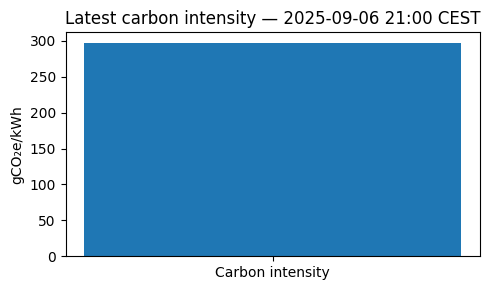

In [15]:
val = ci_series["carbonIntensity_g_per_kWh"]
plt.figure(figsize=(5, 3))
plt.bar(["Carbon intensity"], [val])
plt.ylabel("gCO₂e/kWh")
plt.title(f"Latest carbon intensity — {ci_series.name.strftime('%Y-%m-%d %H:%M %Z')}")
plt.tight_layout()
plt.show()


In [18]:
def get_carbon_intensity_history(params, emission_factor_type="lifecycle"):
    q = dict(params)
    if emission_factor_type:
        q["emissionFactorType"] = emission_factor_type
    url = f"{API_BASE}/carbon-intensity/history"
    return fetch_json(url, HEADERS, q)

def ci_history_to_df(payload):
    rows = payload.get("history", []) or payload.get("data", [])
    if not rows:
        return pd.DataFrame()
    df = pd.json_normalize(rows)
    df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
    df["datetime_local"] = df["datetime"].dt.tz_convert("Europe/Amsterdam")
    df = df.sort_values("datetime").set_index("datetime_local")
    df.rename(columns={"carbonIntensity": "gCO2e_per_kWh"}, inplace=True)
    return df

ci_hist_raw = get_carbon_intensity_history(PARAMS, emission_factor_type="lifecycle")
ci_df = ci_history_to_df(ci_hist_raw)
ci_df.tail(32)


,zone,gCO2e_per_kWh,datetime,updatedAt,createdAt,emissionFactorType,isEstimated,estimationMethod
datetime_local,,,,,,,,
2025-09-05 22:00:00+02:00,NL,496,2025-09-05 20:00:00+00:00,2025-09-06T18:25:28.812Z,2025-09-02T23:30:40.524Z,lifecycle,False,None
2025-09-05 23:00:00+02:00,NL,491,2025-09-05 21:00:00+00:00,2025-09-06T08:40:31.538Z,2025-09-02T23:30:40.524Z,lifecycle,False,None
2025-09-06 00:00:00+02:00,NL,493,2025-09-05 22:00:00+00:00,2025-09-06T18:25:28.797Z,2025-09-02T23:31:00.369Z,lifecycle,False,None
2025-09-06 01:00:00+02:00,NL,490,2025-09-05 23:00:00+00:00,2025-09-06T18:25:28.797Z,2025-09-02T23:31:00.369Z,lifecycle,False,None
2025-09-06 02:00:00+02:00,NL,488,2025-09-06 00:00:00+00:00,2025-09-06T18:25:08.491Z,2025-09-03T23:10:46.897Z,lifecycle,False,None
2025-09-06 03:00:00+02:00,NL,488,2025-09-06 01:00:00+00:00,2025-09-06T18:25:28.797Z,2025-09-03T23:10:32.214Z,lifecycle,False,None
2025-09-06 04:00:00+02:00,NL,479,2025-09-06 02:00:00+00:00,2025-09-06T18:25:28.812Z,2025-09-03T23:41:58.878Z,lifecycle,False,None
2025-09-06 05:00:00+02:00,NL,474,2025-09-06 03:00:00+00:00,2025-09-06T18:25:28.797Z,2025-09-03T23:41:58.878Z,lifecycle,False,None
2025-09-06 06:00:00+02:00,NL,458,2025-09-06 04:00:00+00:00,2025-09-06T18:41:28.579Z,2025-09-03T23:41:58.878Z,lifecycle,False,None
